In [63]:
import pandas as pd
import numpy as np
from merton.extensions.creditgrades import creditgrades_survival
from scipy.integrate import quad_vec
import matplotlib.pyplot as plt

In [64]:
df = pd.read_csv('../Data/aggregation/BA_for_CG.csv')

In [65]:
df.head(2)

,Unnamed: 0.1,Unnamed: 0,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,...,rf,Days_to_maturity,Shares,STD,LTD,sigma_60,sigma_500,sigma_100,IV,sigma_garch_t
0,0,0,2016-01-04,141.380005,141.699997,139.429993,140.500000,126.005096,5719500,0.0,...,NaN,NaN,669983631,614000000,8402000000,NaN,NaN,NaN,NaN,NaN
1,1,1,2016-01-05,140.990005,141.699997,139.770004,141.070007,126.516312,3357000,0.0,...,NaN,NaN,669983631,614000000,8402000000,NaN,NaN,NaN,NaN,NaN


In [66]:
def cg_spread(S, vol, D, T, r, recovery=0.4, lbar=0.5, lam=0.3):
    survival = creditgrades_survival(S, vol, D, T, lbar=lbar, lam=lam)
    annuity = T * quad_vec(
        lambda u: np.exp(-r * T * u) * creditgrades_survival(
            S, vol, D, T * u, lbar=lbar, lam=lam
        ),
        0, 1
    )[0]
    # Непрерывные премии, котировка CDS по ACT/360.
    return (1 - recovery) * ((1 - np.exp(-r * T) * survival) / annuity - r) * 10000 * 360 / 365.25

In [67]:
maturity = pd.Timestamp("2038-02-15")
df["Date"] = pd.to_datetime(df["Date"])
df["T"] = (maturity - df["Date"]).dt.days / 365.25
df["D"] = (df["STD"] + df["LTD"]) / df["Shares"]

result = df[["Date", "Z"]].rename(columns={"Z": "Z_spread"}).copy()
for vol, name in [("sigma_60", "CDS_sigma_60"), ("IV", "CDS_IV"), ("sigma_500", "CDS_sigma_500"),("sigma_100", "CDS_sigma_100"), ("sigma_garch_t", "CDS_sigma_GARCH")]:
    result[name] = np.nan
    x = df.dropna(subset=["Close", "D", "T", "rf", vol])
    x = x[x["T"] > 0]
    result.loc[x.index, name] = cg_spread(
        S=x["Close"].to_numpy(), vol=x[vol].to_numpy(),
        D=x["D"].to_numpy(), T=x["T"].to_numpy(), r=x["rf"].to_numpy() / 100
    )

result

,Date,Z_spread,CDS_sigma_60,CDS_IV,CDS_sigma_500,CDS_sigma_100,CDS_sigma_GARCH
0,2016-01-04,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-01-05,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-01-06,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-01-07,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-01-08,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2728,2026-11-09,143.135848,72.503454,80.593054,73.334607,73.757559,171.054643
2729,2026-11-10,143.135848,70.597681,86.785143,72.738187,73.228525,148.809538
2730,2026-11-11,143.135848,70.347381,83.193747,71.889415,72.883753,128.960810
2731,2026-11-12,143.135848,72.351424,87.735886,72.452938,73.923129,121.513853


In [68]:
result['Date'].dtype

dtype('<M8[ns]')

In [69]:
result = result[
    result['Date'].between('2018-01-01', '2025-01-01', inclusive='neither')
]

В целом, если брать IV, то структурная модель выглядит даже без калибровки осмысленно

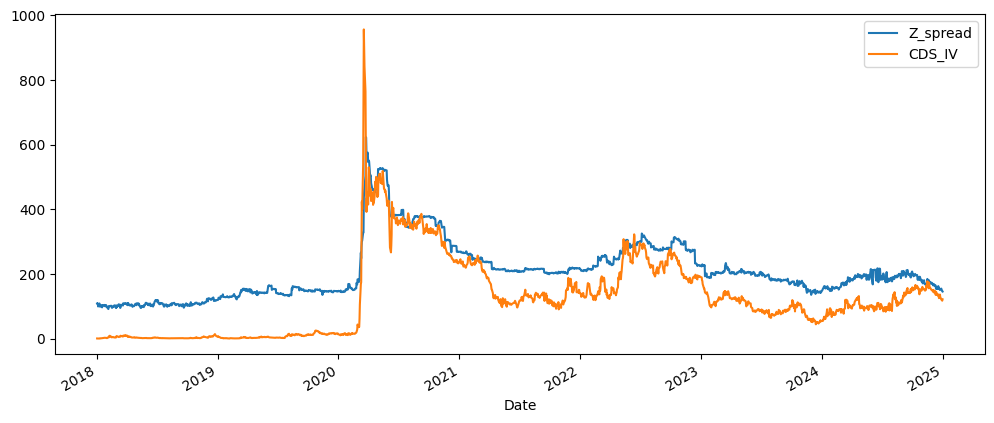

In [70]:
ax = result.plot(x="Date", y="Z_spread", figsize=(12, 5), grid=True)
result.plot(x="Date", y="CDS_IV", ax=ax, secondary_y=False)
plt.show()

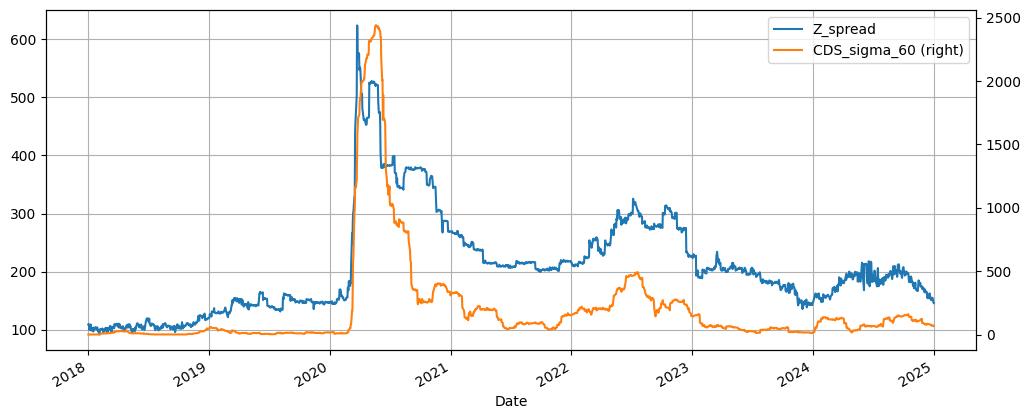

In [71]:
ax = result.plot(x="Date", y="Z_spread", figsize=(12, 5), grid=True)
result.plot(x="Date", y="CDS_sigma_60", ax=ax, secondary_y=True)
plt.show()

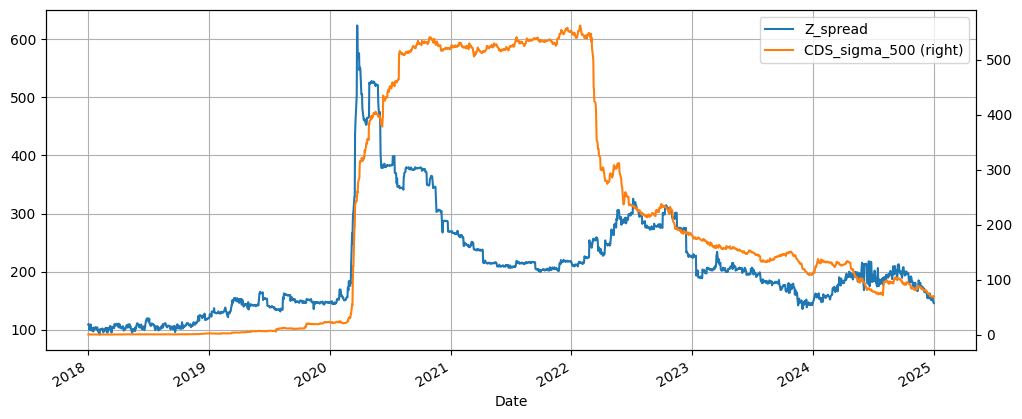

In [72]:
ax = result.plot(x="Date", y="Z_spread", figsize=(12, 5), grid=True)
result.plot(x="Date", y="CDS_sigma_500", ax=ax, secondary_y=True)
plt.show()

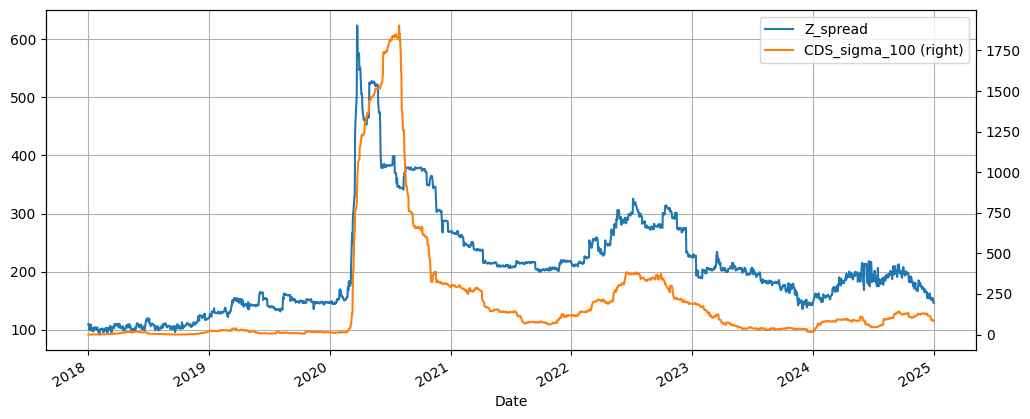

In [73]:
ax = result.plot(x="Date", y="Z_spread", figsize=(12, 5), grid=True)
result.plot(x="Date", y="CDS_sigma_100", ax=ax, secondary_y=True)
plt.show()

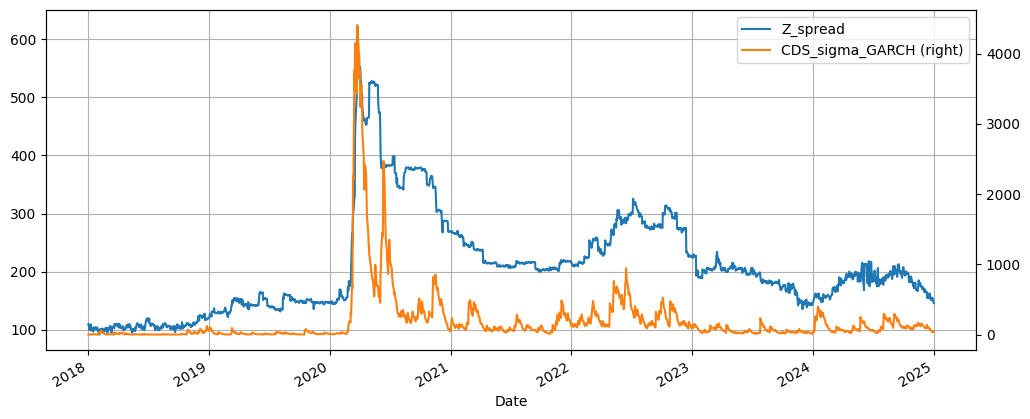

In [74]:
ax = result.plot(x="Date", y="Z_spread", figsize=(12, 5), grid=True)
result.plot(x="Date", y="CDS_sigma_GARCH", ax=ax, secondary_y=True)
plt.show()